# COS40007 Artificial Intelligence Engineering
## Portfolio Assessment 1: Exploratory Data Analysis (EDA) & Data Preparation

**Student Name:** Nguyen Nam Khanh

**Student ID:** 105706565  

**Class Number:** COS40007

**Submission Date:** 01/10/2026

**Dataset:** Seoul Bike Sharing Demand – UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand)

**Generative AI Use Declaration**

"I used Claude Code to assist with debugging code, support design idea, suggesting feature combinations. All final code, interpretations, and conclusions are my own work after verification."


## 1. Dataset Overview & Engineering Relevance

This dataset records hourly bicycle rental counts within Seoul's public bike-sharing system from December 1, 2017, to November 30, 2018, incorporating weather parameters (temperature, humidity, wind speed, precipitation, etc.) and calendar information (seasons, holidays, and operational days). The data was sourced from the UCI Machine Learning Repository (Sathishkumar V. E. et al., 2020). Rental activity is automatically logged by station systems, while weather data is collected from meteorological stations.

From a transportation engineering perspective, forecasting hourly demand enables operators to redistribute bicycles between stations prior to peak periods, schedule maintenance during low-demand times, and plan fleet size and station capacity. Key users of this dataset include system operators and urban transportation planning professionals.

## 2. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42

In [2]:
def label_plot(ax, title, xlabel, ylabel):
    """Apply a title and axis labels to a matplotlib Axes for consistent, well-labelled figures."""
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

## Task 1: Dataset Loading & Initial Exploration

In [3]:
DATA_PATH = "SeoulBikeData.csv"

raw_df = pd.read_csv(DATA_PATH, encoding="latin-1")

column_names = {
    "Date": "date",
    "Rented Bike Count": "rented_bike_count",
    "Hour": "hour",
    "Temperature(°C)": "temperature",
    "Humidity(%)": "humidity",
    "Wind speed (m/s)": "wind_speed",
    "Visibility (10m)": "visibility",
    "Dew point temperature(°C)": "dew_point_temperature",
    "Solar Radiation (MJ/m2)": "solar_radiation",
    "Rainfall(mm)": "rainfall",
    "Snowfall (cm)": "snowfall",
    "Seasons": "seasons",
    "Holiday": "holiday",
    "Functioning Day": "functioning_day",
}
df = raw_df.rename(columns=column_names)

df["date"] = pd.to_datetime(df["date"], format="%d/%m/%Y")

In [4]:
print("Dataset shape:", df.shape)

Dataset shape: (8760, 14)


In [5]:
df.head()

,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall,seasons,holiday,functioning_day
0,2017-12-01,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [6]:
df.dtypes

date                     datetime64[us]
rented_bike_count                 int64
hour                              int64
temperature                     float64
humidity                          int64
wind_speed                      float64
visibility                        int64
dew_point_temperature           float64
solar_radiation                 float64
rainfall                        float64
snowfall                        float64
seasons                             str
holiday                             str
functioning_day                     str
dtype: object

In [7]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,8760,2018-06-01 00:00:00,2017-12-01 00:00:00,2018-03-02 00:00:00,2018-06-01 00:00:00,2018-08-31 00:00:00,2018-11-30 00:00:00,NaN
rented_bike_count,8760.0,704.602055,0.0,191.0,504.5,1065.25,3556.0,644.997468
hour,8760.0,11.5,0.0,5.75,11.5,17.25,23.0,6.922582
temperature,8760.0,12.882922,-17.8,3.5,13.7,22.5,39.4,11.944825
humidity,8760.0,58.226256,0.0,42.0,57.0,74.0,98.0,20.362413
wind_speed,8760.0,1.724909,0.0,0.9,1.5,2.3,7.4,1.0363
visibility,8760.0,1436.825799,27.0,940.0,1698.0,2000.0,2000.0,608.298712
dew_point_temperature,8760.0,4.073813,-30.6,-4.7,5.1,14.8,27.2,13.060369
solar_radiation,8760.0,0.569111,0.0,0.0,0.01,0.93,3.52,0.868746
rainfall,8760.0,0.148687,0.0,0.0,0.0,0.0,35.0,1.128193


In [8]:
df.select_dtypes(exclude=["number", "datetime"]).describe().T

,count,unique,top,freq
seasons,8760,4,Spring,2208
holiday,8760,2,No Holiday,8328
functioning_day,8760,2,Yes,8465


In [9]:
df.isnull().sum()

date                     0
rented_bike_count        0
hour                     0
temperature              0
humidity                 0
wind_speed               0
visibility               0
dew_point_temperature    0
solar_radiation          0
rainfall                 0
snowfall                 0
seasons                  0
holiday                  0
functioning_day          0
dtype: int64

### Task 1 – Observations
Dimensions: 8,760 rows × 14 columns, corresponding to 365 days × 24 hours.
Data types:
1 time column: date, converted to datetime format.
10 numeric columns: 4 integers and 6 floats, including the target variable.
3 categorical columns: Seasons (4 values), Holiday (2), Working_day (2).
Target variable (`rented_bike_count`):
Mean: ~705; Median: 504.5; Maximum: 3,556.
The mean exceeds the median, indicating a right-skewed distribution.
Minimum = 0.
No missing values ​​in any column.

## Task 2: Data Quality Assessment

In [10]:
# Missing values table with percentages
missing_table = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": df.isnull().mean() * 100,
})
missing_table

,missing_count,missing_percent
date,0,0.0
rented_bike_count,0,0.0
hour,0,0.0
temperature,0,0.0
humidity,0,0.0
wind_speed,0,0.0
visibility,0,0.0
dew_point_temperature,0,0.0
solar_radiation,0,0.0
rainfall,0,0.0


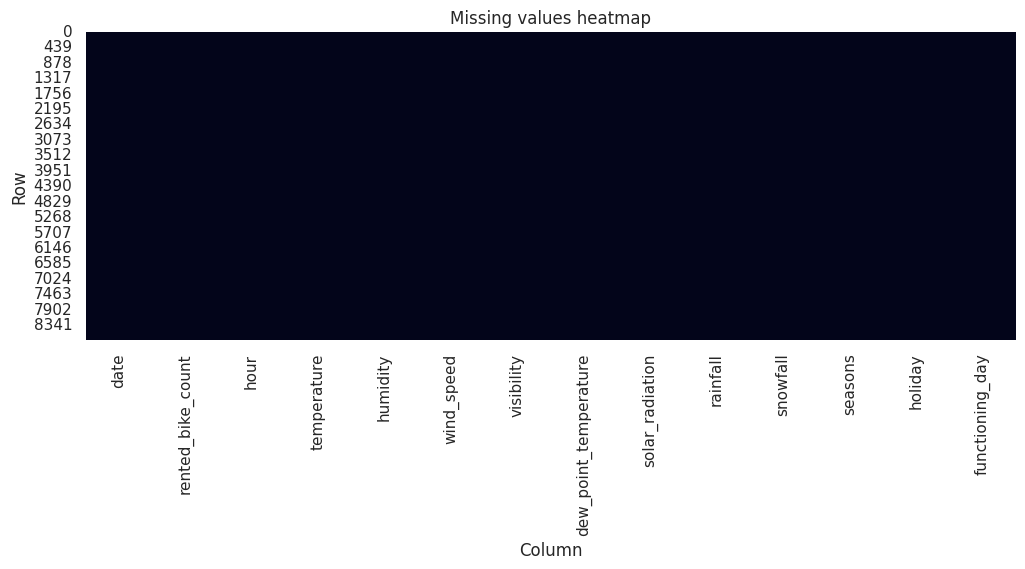

In [11]:
# Missing values heatmap
plt.figure(figsize=(12, 4))
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing values heatmap")
plt.xlabel("Column")
plt.ylabel("Row")
plt.show()

In [12]:
# Duplicate count and examples
print("Number of duplicated rows:", df.duplicated().sum())
df[df.duplicated()]

Number of duplicated rows: 0


,date,rented_bike_count,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall,seasons,holiday,functioning_day


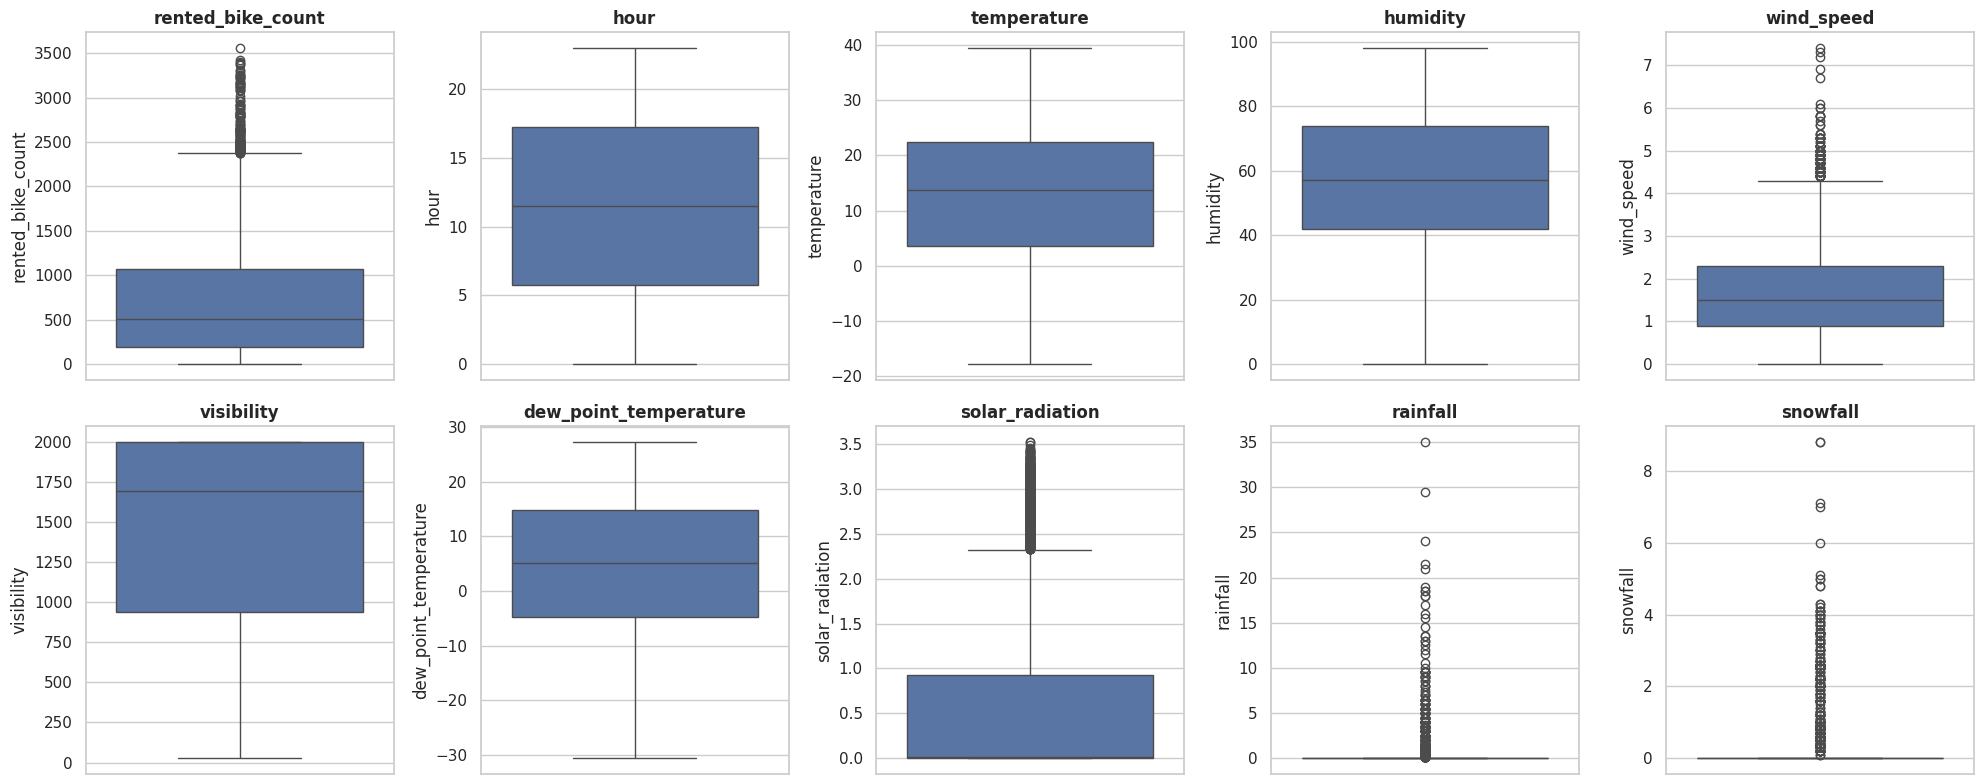

In [13]:
# Boxplots for all numerical features
numeric_cols = ["rented_bike_count", "hour", "temperature", "humidity", "wind_speed",
                "visibility", "dew_point_temperature", "solar_radiation", "rainfall", "snowfall"]

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(y=df[col], ax=ax)
    label_plot(ax, col, "", col)
plt.tight_layout()
plt.show()

### Task 2 – Observations about data quality
Dimensions: 8,760 rows × 14 columns (corresponding to 365 days × 24 hours).
Data types:
1 time column: date (converted to datetime format).
10 numeric columns: 4 integers and 6 floats (including the target variable).
3 categorical columns: Seasons (4 values), Holiday (2 values), Working_day (2 values).
Target variable (`rented_bike_count`):
Mean: ~705; Median: 504.5; Maximum: 3,556.
The mean exceeds the median, indicating a right-skewed distribution.
Minimum = 0.
There are no missing values ​​across any columns; however, some values ​​are not meaningful. For instance, in the `functioning_day` column, a value of "No" indicates the system is closed and no bikes are rented (observed in 295 instances); during these hours, `rented_bike_count` is always 0, making them irrelevant for calculating rental demand. Additionally, a humidity value of 0 is unrealistic—likely due to a sensor error—and should be removed to avoid negatively impacting the model.

In [14]:
# Work on a copy so the raw data stays untouched
df_clean = df.copy()

print("Non-functioning hours removed:", (df_clean["functioning_day"] == "No").sum())
df_clean = df_clean[df_clean["functioning_day"] == "Yes"]
df_clean = df_clean.drop(columns="functioning_day")

print("Rows with humidity = 0 removed:", (df_clean["humidity"] == 0).sum())
df_clean = df_clean[df_clean["humidity"] != 0]

Non-functioning hours removed: 295
Rows with humidity = 0 removed: 17


In [15]:
# Dataset shape and data types after cleaning
print("Shape before cleaning:", df.shape)
print("Shape after cleaning: ", df_clean.shape)
df_clean.dtypes

Shape before cleaning: (8760, 14)
Shape after cleaning:  (8448, 13)


date                     datetime64[us]
rented_bike_count                 int64
hour                              int64
temperature                     float64
humidity                          int64
wind_speed                      float64
visibility                        int64
dew_point_temperature           float64
solar_radiation                 float64
rainfall                        float64
snowfall                        float64
seasons                             str
holiday                             str
dtype: object

## Task 3: Target Variable Preparation

In [16]:
# Target name, dtype and summary statistics
TARGET = "rented_bike_count"
print("Target:", TARGET)
print("Data type:", df_clean[TARGET].dtype)
print("Skewness:", round(df_clean[TARGET].skew(), 2))
df_clean[TARGET].describe()

Target: rented_bike_count
Data type: int64
Skewness: 1.14


count    8448.000000
mean      729.803977
std       642.628017
min         2.000000
25%       214.000000
50%       544.500000
75%      1084.250000
max      3556.000000
Name: rented_bike_count, dtype: float64

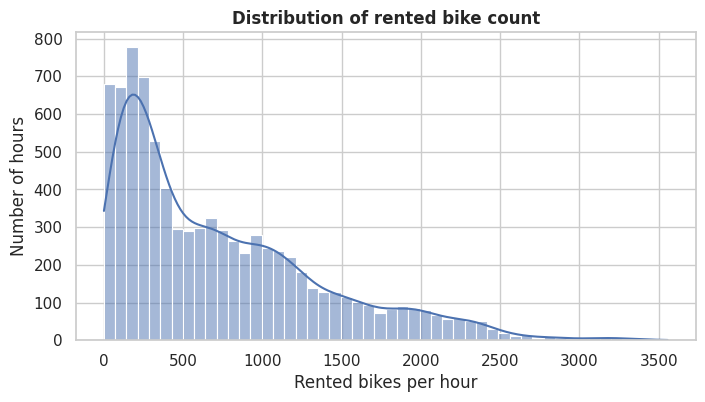

In [17]:
# Target distribution (histogram / KDE)
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df_clean[TARGET], bins=50, kde=True, ax=ax)
label_plot(ax, "Distribution of rented bike count", "Rented bikes per hour", "Number of hours")
plt.show()

In [18]:
labels = ["Low", "Medium", "High"]

# Option A: equal-width bins
print("pd.cut (equal-width):")
print(pd.cut(df_clean[TARGET], bins=3, labels=labels).value_counts())

# Option B: equal-frequency bins (chosen, because the target is right-skewed)
df_clean["demand_class"] = pd.qcut(df_clean[TARGET], q=3, labels=labels)
print("\npd.qcut (equal-frequency):")
print(df_clean["demand_class"].value_counts())

df_clean.groupby("demand_class")[TARGET].agg(["min", "max"])

pd.cut (equal-width):
rented_bike_count
Low       6657
Medium    1630
High       161
Name: count, dtype: int64

pd.qcut (equal-frequency):
demand_class
Low       2816
Medium    2816
High      2816
Name: count, dtype: int64


,min,max
demand_class,,
Low,2,285
Medium,286,896
High,897,3556


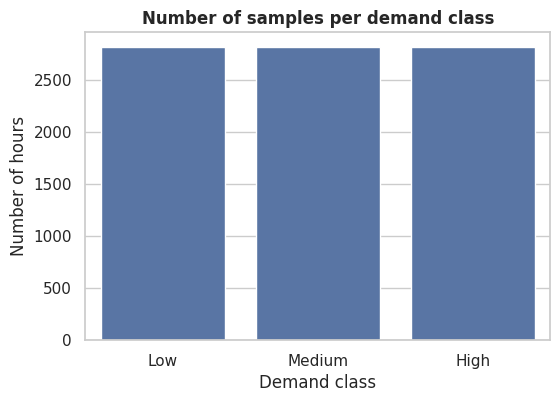

In [19]:
# Class distribution plot
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x=df_clean["demand_class"], ax=ax)
label_plot(ax, "Number of samples per demand class", "Demand class", "Number of hours")
plt.show()

MD_T3

## Task 4: Univariate Analysis

In [20]:
# List of predictors
numerical_predictors = ["hour", "temperature", "humidity", "wind_speed", "visibility",
                        "dew_point_temperature", "solar_radiation", "rainfall", "snowfall"]
categorical_predictors = ["seasons", "holiday"]
print("Numerical predictors:", numerical_predictors)
print("Categorical predictors:", categorical_predictors)

Numerical predictors: ['hour', 'temperature', 'humidity', 'wind_speed', 'visibility', 'dew_point_temperature', 'solar_radiation', 'rainfall', 'snowfall']
Categorical predictors: ['seasons', 'holiday']


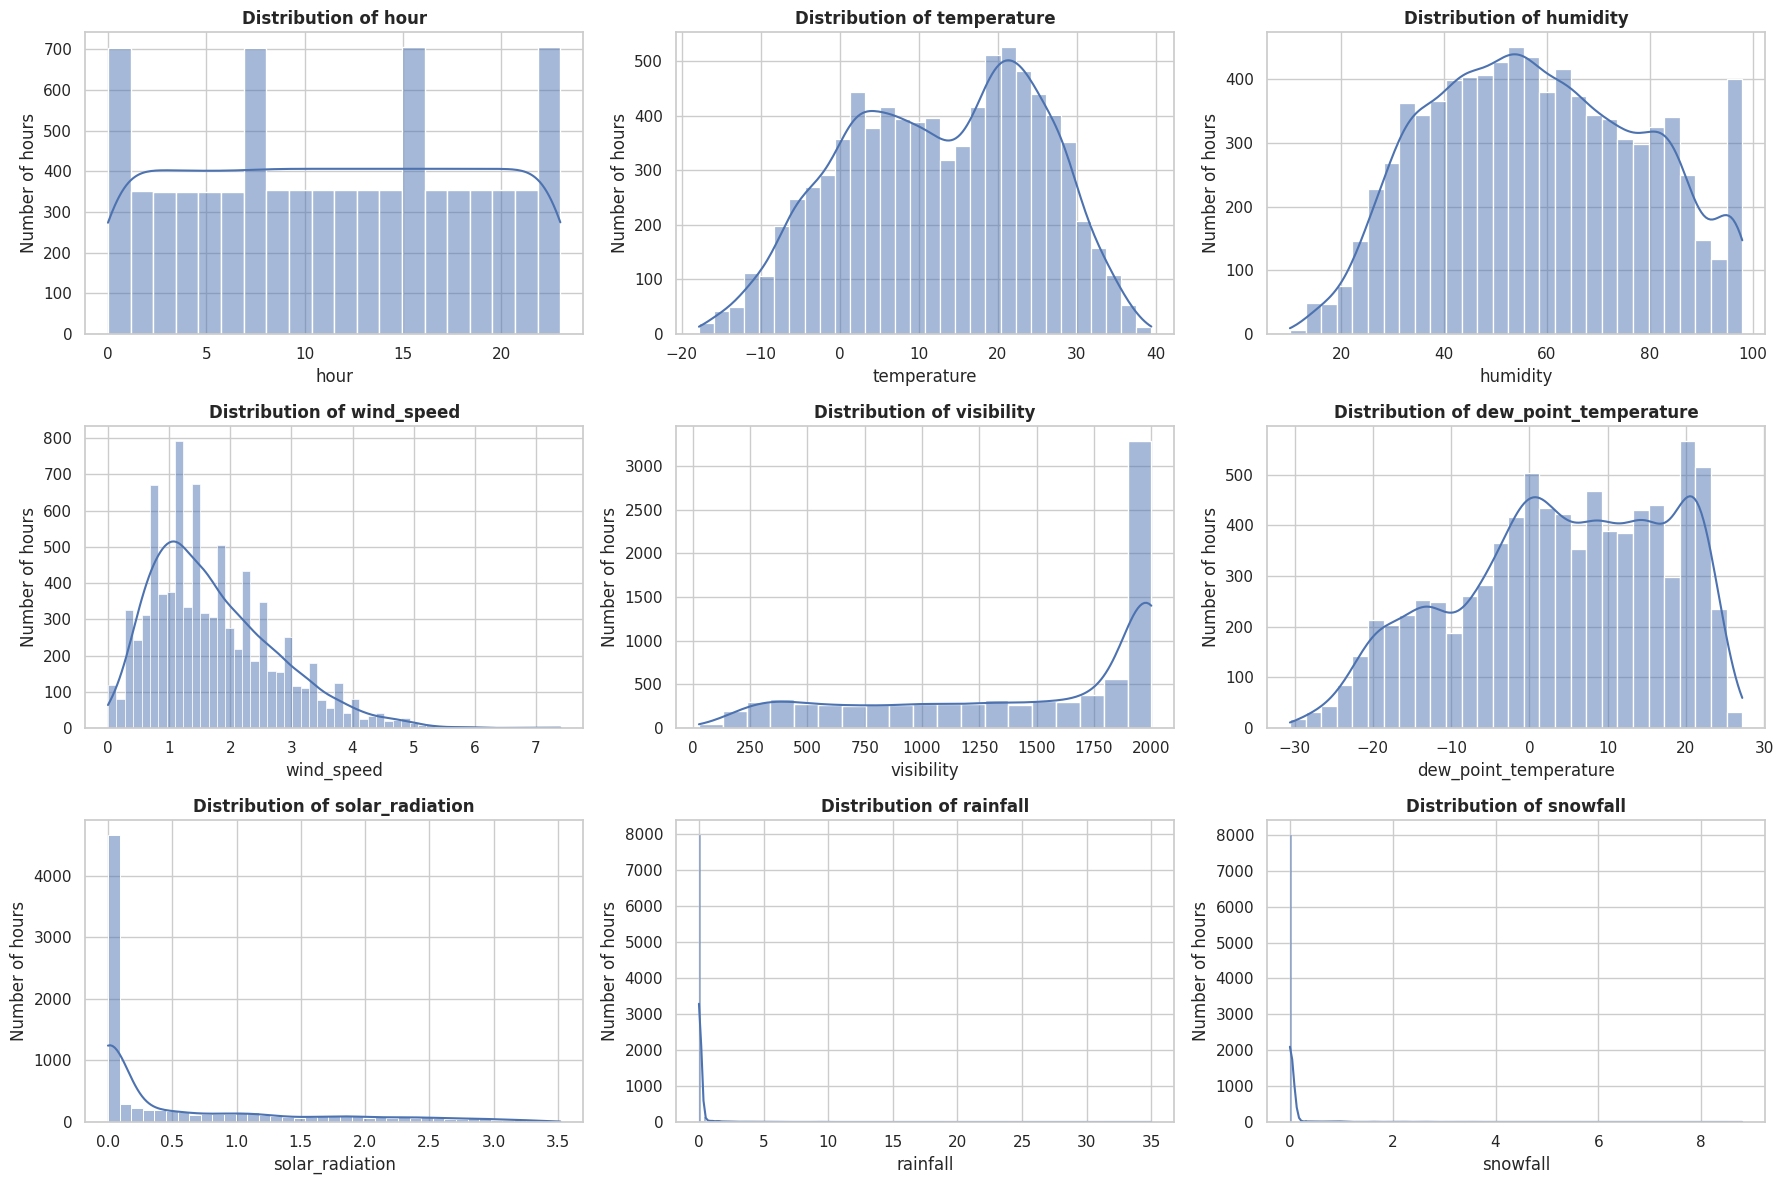

In [21]:
# Distribution plots for numerical predictors
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
for ax, col in zip(axes.flat, numerical_predictors):
    sns.histplot(df_clean[col], kde=True, ax=ax)
    label_plot(ax, "Distribution of " + col, col, "Number of hours")
plt.tight_layout()
plt.show()

In [22]:
# Summary statistics table (incl. skewness and kurtosis)
summary_stats = df_clean[numerical_predictors].describe().T
summary_stats["skewness"] = df_clean[numerical_predictors].skew()
summary_stats["kurtosis"] = df_clean[numerical_predictors].kurt()
summary_stats.round(2)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
hour,8448.0,11.52,6.92,0.0,6.00,12.00,18.00,23.00,-0.00,-1.20
temperature,8448.0,12.77,12.12,-17.8,3.00,13.45,22.70,39.40,-0.17,-0.89
humidity,8448.0,58.26,20.34,10.0,42.00,57.00,74.00,98.00,0.10,-0.88
wind_speed,8448.0,1.73,1.03,0.0,0.90,1.50,2.30,7.40,0.89,0.75
visibility,8448.0,1433.36,609.42,27.0,933.75,1690.00,2000.00,2000.00,-0.69,-0.97
dew_point_temperature,8448.0,3.94,13.25,-30.6,-5.20,4.70,15.20,27.20,-0.34,-0.82
solar_radiation,8448.0,0.57,0.87,0.0,0.00,0.01,0.93,3.52,1.51,1.14
rainfall,8448.0,0.15,1.13,0.0,0.00,0.00,0.00,35.00,14.60,289.38
snowfall,8448.0,0.08,0.44,0.0,0.00,0.00,0.00,8.80,8.28,90.35


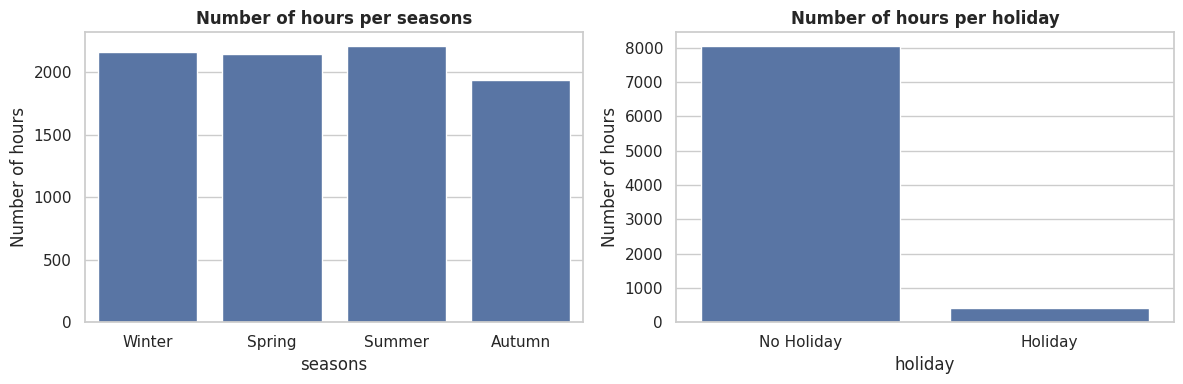

In [23]:
# Categorical predictors
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, categorical_predictors):
    sns.countplot(x=df_clean[col], ax=ax)
    label_plot(ax, "Number of hours per " + col, col, "Number of hours")
plt.tight_layout()
plt.show()

### Task 4 – Observations about distributions
Temperature, humidity, and dew point temperature are approximately symmetric, while hour is uniformly distributed. Wind speed is moderately right-skewed, whereas visibility is moderately left-skewed due to its upper limit. Rainfall and snowfall are highly right-skewed with many zero values, and solar radiation also contains many zeros due to nighttime. Seasons are relatively balanced, while holidays are highly imbalanced. These skewed and zero-heavy features may require transformations or binary indicators before modelling.

## Task 5: Multivariate Analysis

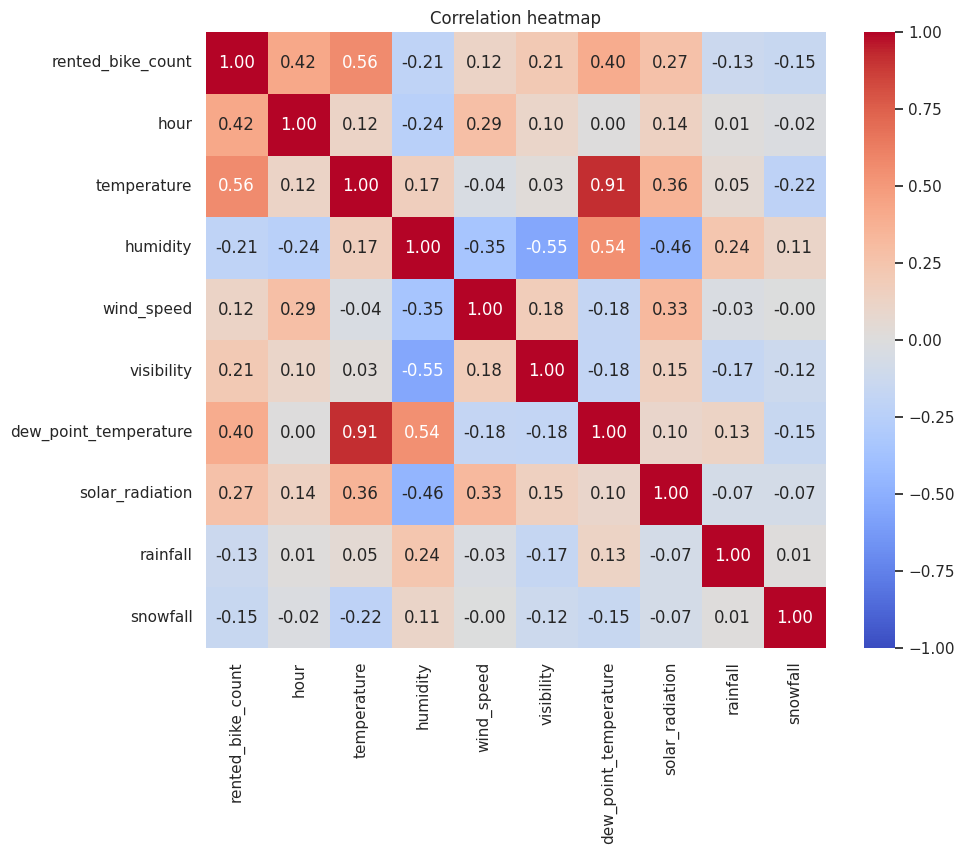

In [24]:
# Correlation heatmap
corr = df_clean[[TARGET] + numerical_predictors].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap")
plt.show()

In [25]:
# Top 3 features correlated with the target (sorted by absolute value)
target_corr = corr[TARGET].drop(TARGET)
top3 = target_corr.abs().sort_values(ascending=False).head(3)
for feature in top3.index:
    print(feature, round(target_corr[feature], 3))

temperature 0.563
hour 0.425
dew_point_temperature 0.401


In [26]:
# Multicollinearity check: predictor pairs with |r| > 0.7
for i in range(len(numerical_predictors)):
    for j in range(i + 1, len(numerical_predictors)):
        f1 = numerical_predictors[i]
        f2 = numerical_predictors[j]
        r = corr.loc[f1, f2]
        if abs(r) > 0.7:
            print(f1, "-", f2, ":", round(r, 3))

temperature - dew_point_temperature : 0.915


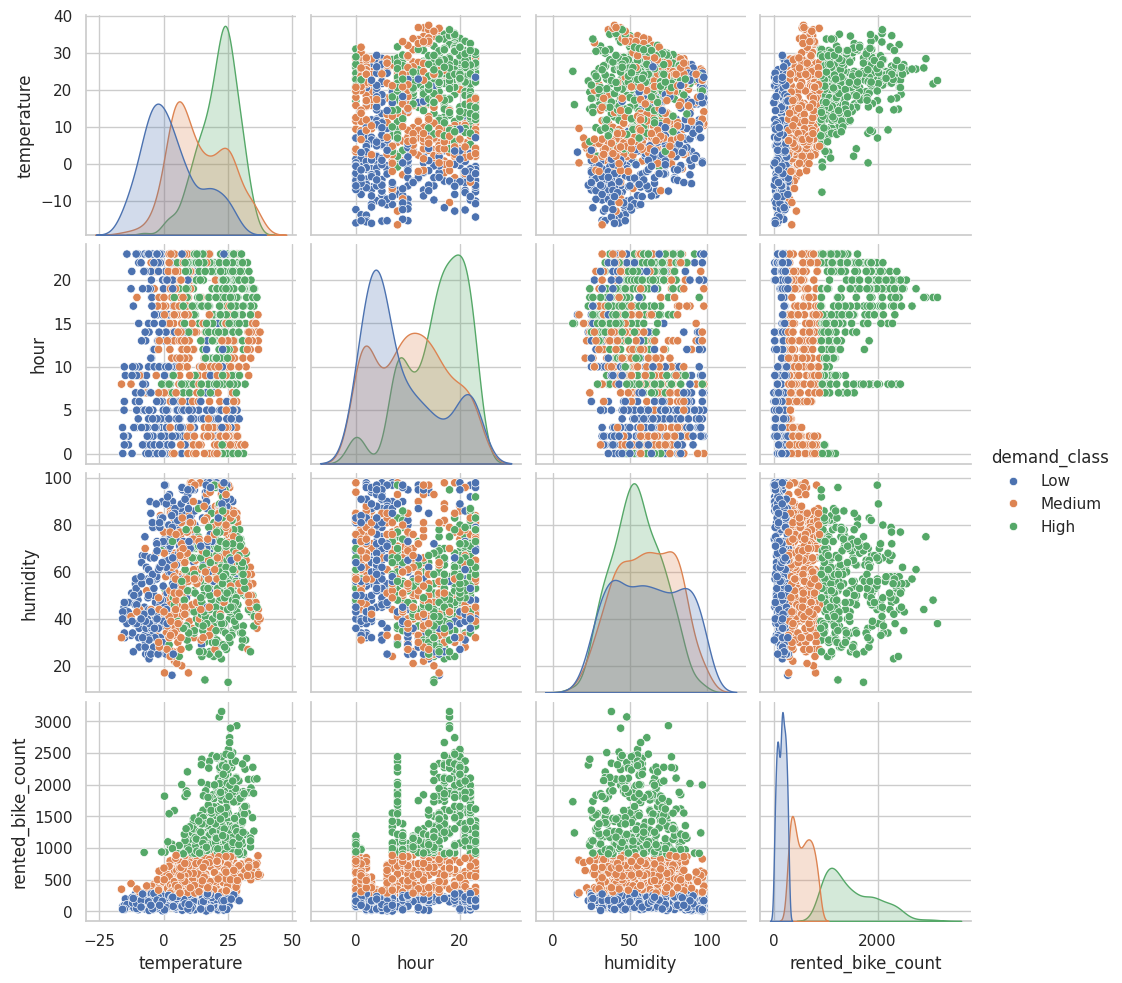

In [27]:
# Pairplot of key features (1,000-row sample for speed)
sample = df_clean.sample(n=1000, random_state=RANDOM_STATE)
sns.pairplot(sample, vars=["temperature", "hour", "humidity", TARGET], hue="demand_class")
plt.show()

### Task 5 – Observations about relationships and patterns
- **Top 3 features correlated with the target:**
  1. [temperature] – [0.565]
  2. [hour] – [0.425]
  3. [dew_point_temperature] – [0.401]
- **Multicollinearity:** 
 Only one pair exceeds |r| > 0.7: temperature and dew_point_temperature (r = 0.915). This is expected physically, since dew point is derived from temperature and humidity. Dew point adds little new information, so it could be dropped and temperature kept. All other predictor pairs are below 0.6.
- **Patterns:** 
 Demand shows clear non-linear daily and seasonal patterns, with peaks during commuting hours and highest demand in summer. Rain and holidays are associated with lower demand, while pairplot overlap indicates that no single feature clearly separates demand levels. This suggests that non-linear models may be more suitable for prediction.

## Initial Insights for Modelling

- **Most promising features:** temperature, hour, seasons, rainfall, and humidity
- **Preprocessing needed:**
  - Scaling:: Apply StandardScaler to numerical features for KNN, SVM, and Logistic Regression.
  - Encoding: One-hot encode seasons and convert holiday to binary.
  - Feature selection: Drop dew_point_temperature due to high correlation with temperature, and drop date. Consider binary flags for rainfall/snowfall due to many zero values.
- **Modelling approaches that might work well:** Tree-based models such as Decision Tree, Random Forest, and Gradient Boosting can capture non-linear patterns. Logistic Regression can be used as a baseline.

## Task 6: Engineering Interpretation
1. What do the correlations mean in engineering terms?
- Temperature (r = 0.563) has the strongest relationship with bike demand, as people are more likely to cycle when the weather is comfortable. Hour (r = 0.425) is also important because demand follows daily commuting patterns. Humidity, rainfall, and snowfall have negative relationships with demand, as wet or snowy conditions can make cycling less comfortable. Overall, weather conditions and time of day are the main factors to consider when planning bike supply.
2. Are there any unexpected patterns from an engineering perspective?
- Rainfall has a weak correlation (r = -0.13), but demand drops significantly from 766 to 167 bikes/hour when it rains. This suggests that simply whether it rains matters more than the amount of rainfall.
The evening peak at 18:00 (≈1,554) is much higher than the morning peak at 8:00 (≈1,050), suggesting that bike usage patterns differ between morning and evening commuting.
Dew point has a relatively high correlation with demand, but it is strongly correlated with temperature (r = 0.915), so it may not provide much additional information.
3. What physical/process relationships do the data reflect?
- Atmospheric physics:
Dew point is derived from temperature and humidity (r = 0.915 with temperature).       
High humidity is linked to lower visibility (r = -0.55), from fog and haze. 
High humidity is also linked to less solar radiation (r = -0.46), from cloud cover.
Solar radiation is zero at night (49% of hours).
- Human/process behaviour:
Commuting creates the two daily peaks.
Holidays lower demand (532 vs 740) because fewer people commute.
Seasons change demand roughly fivefold (winter 226 vs summer 1,034).
- Sensor behaviour:
Visibility is capped at 2,000 (20 km).
Humidity = 0 readings are sensor faults rather than real conditions.
4. Based on your engineering knowledge, are there any missing features that would be important?
- Day of week / weekend flag: commuting patterns differ strongly between weekdays and weekends, and the dataset only marks public holidays.
- Station location and bike availability: demand is recorded city-wide, but rebalancing decisions are made per station.
- Air quality (PM2.5 / fine dust): a known factor in Seoul that discourages outdoor activity.
- Public transport status and special events: subway disruptions, festivals or sports events can cause sudden demand spikes.
5. What type of model might suit this dataset, and why?
- Tree-based models: Random Forest and Gradient Boosting are suitable because they handle non-linear relationships, mixed feature types, and skewed variables without scaling.
- Interpretability: Feature importance can help identify the main drivers of demand.
- Baseline: Logistic Regression provides a simple and interpretable baseline.
- Evaluation: Since the classes are balanced (2,816 each), Accuracy and F1-score are appropriate metrics.



## Task 7: Challenges Encountered
- File encoding: The CSV could not be read with UTF-8 because of the "°" symbol in column names, so I loaded it with latin-1 and renamed the columns.
- Hidden data problems: The dataset had no missing values or duplicates, but further checks revealed 295 closed hours (target always 0) and 17 rows with humidity = 0 (sensor errors). I removed both, since they do not represent real demand or real conditions.
- Outliers: Instead of removing extreme values automatically, I kept them because heavy rain, snow and rush-hour peaks are real events the model needs to learn.
- Target binning: The target is right-skewed, so equal-width binning left only 161 samples in the High class. I compared it with equal-frequency binning and chose the latter to get balanced classes (2,816 each).
- Feature analysis: Correlation alone was misleading for rainfall (r = -0.13), but comparing group averages showed demand drops from 766 to 167 bikes/hour when it rains, so group analysis was needed alongside correlation.
- Visualisation: The original pairplot was too cluttered, so I reduced it to the key features and removed dew point, which duplicates temperature (r = 0.915).

## Task 8: Responsible AI Reflection
- **How might poor data quality affect model reliability?**

    Sensor errors: Faulty readings such as humidity = 0% teach the model false relationships, so new data must also be validated before prediction.

    Few extreme-weather examples: Rainfall and snowfall are about 94% zeros, so the model may perform poorly in heavy rain or snow, exactly when operators need accurate forecasts.

    Outdated data: The data covers only one year (2017–2018), so changes in stations, prices or travel habits will reduce accuracy over time unless the model is retrained.
- **What ethical or bias issues might exist in this dataset?**

    Unmet demand is not recorded: When a station is empty, people cannot rent a bike, so the data underestimates real demand and a model could keep under-supplying busy areas.

    No location data: Demand is aggregated city-wide, so decisions may favour busy central areas and neglect outer or lower-income neighbourhoods.

    Only current users are represented: People who do not or cannot use the service (e.g. older people or people with disabilities) are invisible in the data, so their needs may be ignored.



## Next Steps
* **Add a weekday/weekend feature:** Extract the day of the week from `date` to see whether the morning and evening peaks are mainly caused by commuting on working days.
* **Explore feature interactions:** Check how features such as temperature and hour work together, and whether rain has a stronger effect during peak hours.
* **Transform skewed features:** Test rain/snow indicators and log transformations for `rainfall` and `snowfall` to see which representation works better.
* **Build baseline models:** Train Logistic Regression and Random Forest to validate the insights from the EDA and compare the effect of removing features such as dew point.
* **Collect more data:** Include station-level information, air quality data such as PM2.5, and data from more years to reduce the limitations identified in Task 8.


## Task 9: Summary

 This task will be done in the pdf file.

# Portfolio Assessment 2

## Task 1: Target Variable Preparation

In [28]:
labels = ["Low", "Medium", "High"]
df_clean["demand_class"], bin_edges = pd.qcut(df_clean[TARGET], q=3, labels=labels, retbins=True)

print("Bin edges:", bin_edges)
df_clean["demand_class"].value_counts()

Bin edges: [2.00000000e+00 2.85666667e+02 8.96333333e+02 3.55600000e+03]


demand_class
Low       2816
Medium    2816
High      2816
Name: count, dtype: int64

## Task 2: Feature Normalisation & Transformation
### 2.1 Normalise numerical features

In [29]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

df_model = df_clean.copy()
num = df_model[numerical_predictors]

# Distribution of each feature, used to choose the scaler
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
distribution = pd.DataFrame({
    "skewness": num.skew(),
    "outlier_%": ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).mean() * 100,
    "zero_%": (num == 0).mean() * 100,
})
distribution.round(2)

,skewness,outlier_%,zero_%
hour,-0.00,0.00,4.17
temperature,-0.17,0.00,0.25
humidity,0.10,0.00,0.00
wind_speed,0.89,1.82,0.84
visibility,-0.69,0.00,0.00
dew_point_temperature,-0.34,0.00,0.71
solar_radiation,1.51,7.34,49.02
rainfall,14.60,6.11,93.89
snowfall,8.28,5.24,94.76


In [30]:
standard_cols = ["temperature", "humidity", "dew_point_temperature"]  # near-normal
minmax_cols = ["hour", "visibility"]                                  # uniform / bounded
robust_cols = ["wind_speed", "solar_radiation"]                       # has outliers
log_cols = ["rainfall", "snowfall"]                                   # extremely skewed, ~94% zeros

X_num = num.copy()
X_num[standard_cols] = StandardScaler().fit_transform(X_num[standard_cols])
X_num[minmax_cols] = MinMaxScaler().fit_transform(X_num[minmax_cols])
X_num[robust_cols] = RobustScaler().fit_transform(X_num[robust_cols])
X_num[log_cols] = MinMaxScaler().fit_transform(np.log1p(X_num[log_cols]))

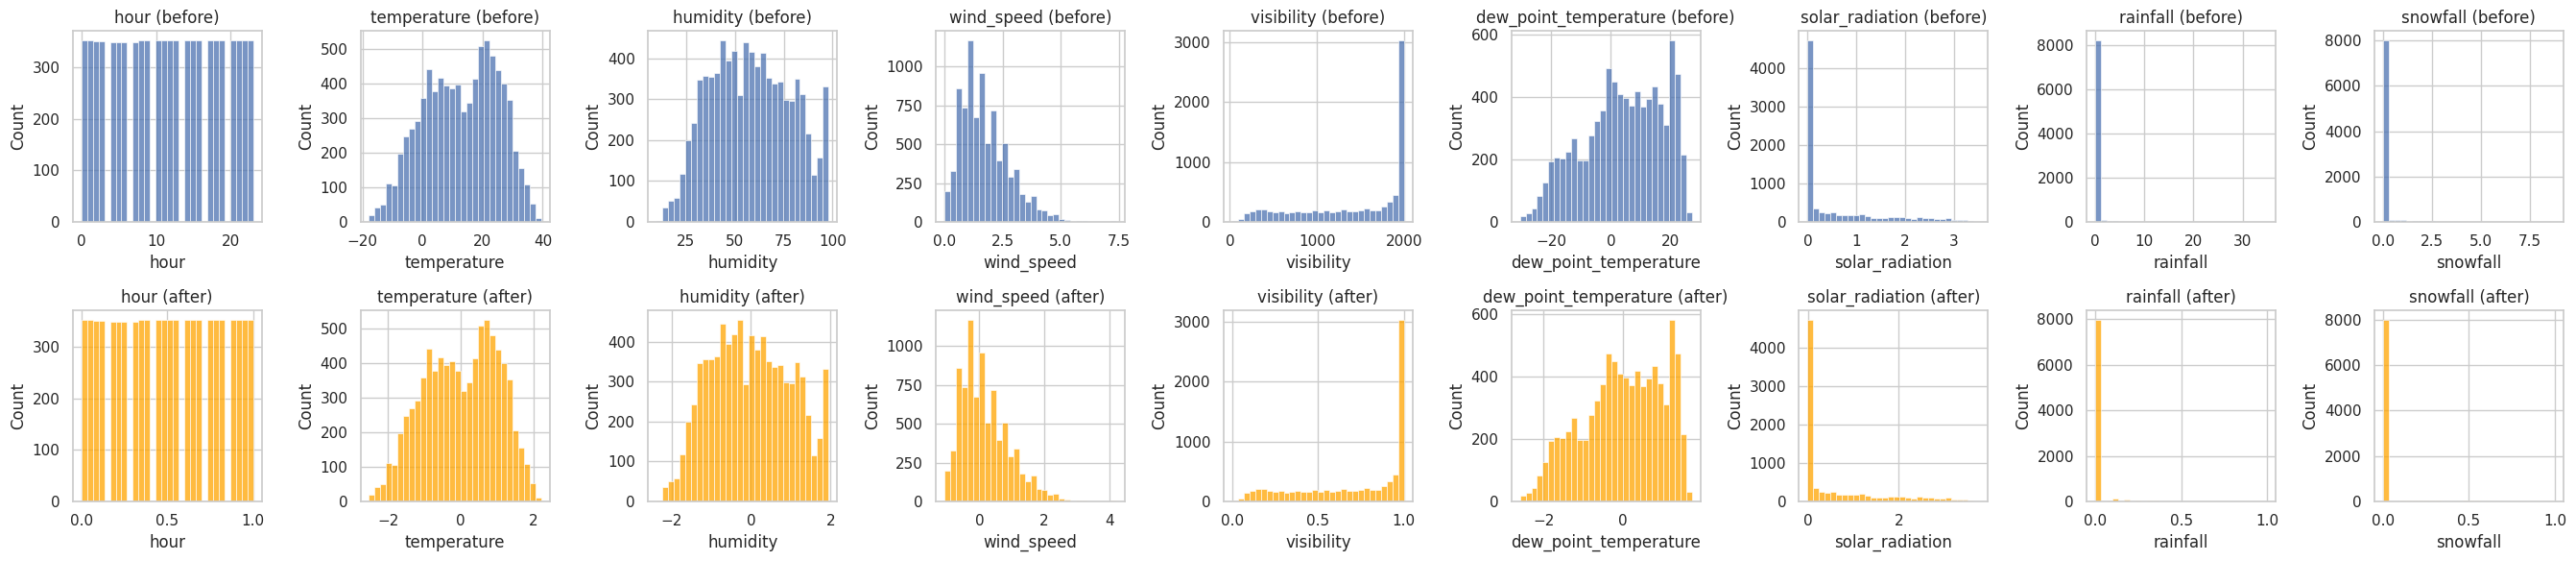

In [31]:
# Before / after scaling comparison
fig, axes = plt.subplots(2, 9, figsize=(27, 6))
for i, col in enumerate(numerical_predictors):
    sns.histplot(num[col], bins=30, ax=axes[0, i])
    sns.histplot(X_num[col], bins=30, ax=axes[1, i], color="orange")
    axes[0, i].set_title(col + " (before)")
    axes[1, i].set_title(col + " (after)")
plt.tight_layout()
plt.show()

### 2.2 Encode categorical features

In [32]:
X_cat = pd.DataFrame(index=df_model.index)
X_cat["holiday"] = (df_model["holiday"] == "Holiday").astype(int)                       # binary 0/1
X_cat = X_cat.join(pd.get_dummies(df_model["seasons"], prefix="season", dtype=int))   # one-hot

X = pd.concat([X_num, X_cat], axis=1)
y = df_model["demand_class"].map({"Low": 0, "Medium": 1, "High": 2}).astype(int)

print("X shape:", X.shape)
X.head()

X shape: (8448, 14)


,hour,temperature,humidity,wind_speed,visibility,dew_point_temperature,solar_radiation,rainfall,snowfall,season_Autumn,season_Spring,season_Summer,season_Winter,holiday
0,0.000000,-1.483031,-1.045576,0.500000,1.0,-1.625587,-0.010753,0.0,0.0,0,0,0,1,0
1,0.043478,-1.507794,-0.996406,-0.500000,1.0,-1.625587,-0.010753,0.0,0.0,0,0,0,1,0
2,0.086957,-1.549064,-0.947235,-0.357143,1.0,-1.633133,-0.010753,0.0,0.0,0,0,0,1,0
3,0.130435,-1.565573,-0.898064,-0.428571,1.0,-1.625587,-0.010753,0.0,0.0,0,0,0,1,0
4,0.173913,-1.549064,-1.094747,0.571429,1.0,-1.701045,-0.010753,0.0,0.0,0,0,0,1,0


## Task 3: Feature Engineering

In [33]:
eng = pd.DataFrame(index=df_model.index)
eng["temp_x_hour"] = df_model["temperature"] * df_model["hour"]
eng["hour_sin"] = np.sin(2 * np.pi * df_model["hour"] / 24)
eng["hour_cos"] = np.cos(2 * np.pi * df_model["hour"] / 24)
eng["is_weekend"] = (df_model["date"].dt.dayofweek >= 5).astype(int)
eng["rush_workday"] = (df_model["hour"].isin([7, 8, 9, 17, 18, 19])
                       & (eng["is_weekend"] == 0)
                       & (df_model["holiday"] == "No Holiday")).astype(int)
eng["is_raining"] = (df_model["rainfall"] > 0).astype(int)
eng["daily_rainfall"] = df_model.groupby("date")["rainfall"].transform("sum")

# Check relationship with the target
eng.corrwith(df_model[TARGET]).round(3)

temp_x_hour       0.700
hour_sin         -0.448
hour_cos         -0.102
is_weekend       -0.047
rush_workday      0.329
is_raining       -0.223
daily_rainfall   -0.152
dtype: float64

In [34]:
eng_scaled = eng.copy()
eng_scaled["temp_x_hour"] = StandardScaler().fit_transform(eng[["temp_x_hour"]]).ravel()
eng_scaled["daily_rainfall"] = MinMaxScaler().fit_transform(np.log1p(eng[["daily_rainfall"]])).ravel()

X_eng = pd.concat([X, eng_scaled], axis=1)
print("X_eng shape:", X_eng.shape)

X_eng shape: (8448, 21)


temp_x_hour              0.700
temperature              0.563
hour_sin                -0.448
hour                     0.425
dew_point_temperature    0.401
rush_workday             0.329
solar_radiation          0.273
is_raining              -0.223
visibility               0.213
humidity                -0.207
dtype: float64


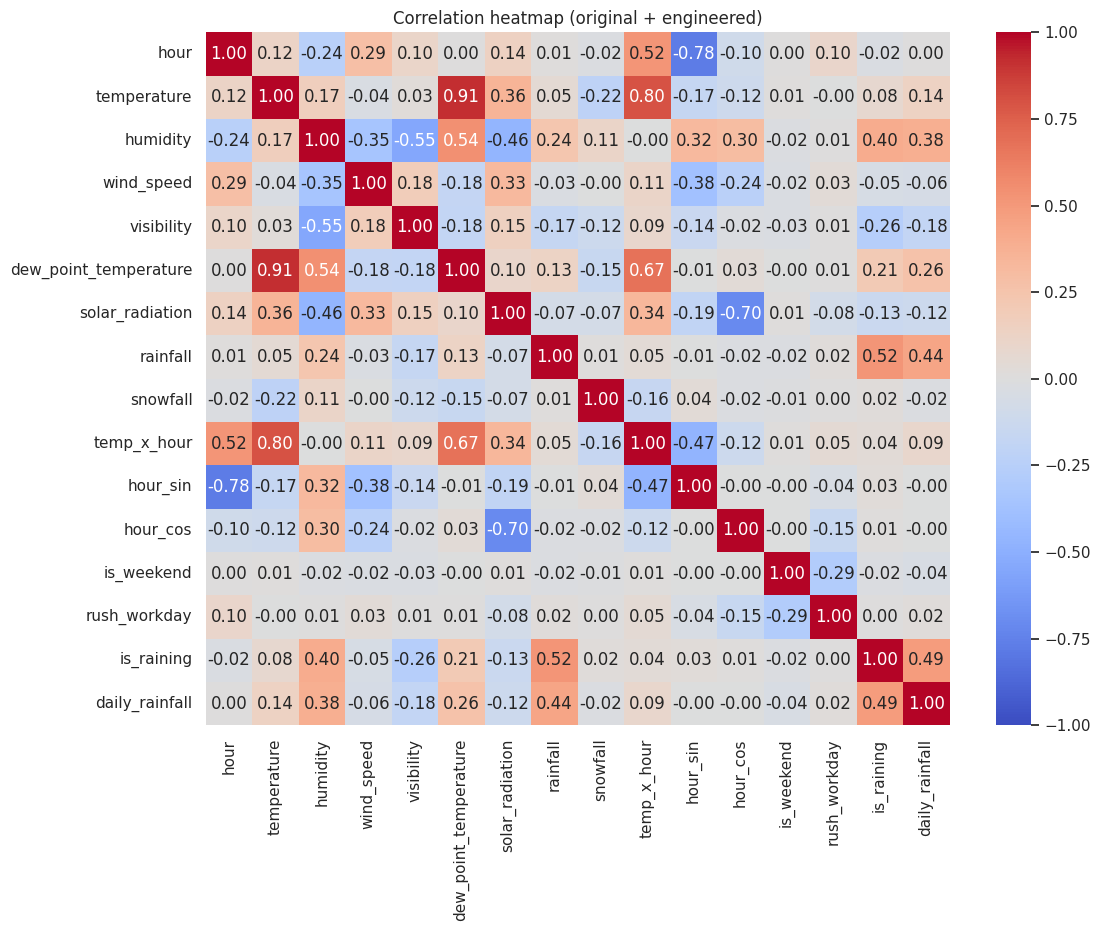

In [35]:
# Top correlations with the target and multicollinearity
all_features = pd.concat([df_model[numerical_predictors], eng], axis=1)
corr_target = all_features.corrwith(df_model[TARGET])
print(corr_target.sort_values(key=abs, ascending=False).head(10).round(3))

plt.figure(figsize=(12, 9))
sns.heatmap(all_features.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap (original + engineered)")
plt.show()

## Task 4: Decision Tree Modelling & Comparison

In [36]:
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA

X_raw = pd.concat([num, X_cat], axis=1)
top5 = corr_target.abs().sort_values(ascending=False).head(5).index

feature_sets = {
    "Set 1: Original (raw)": X_raw,
    "Set 2: Original (normalised)": X,
    "Set 3: Normalised + engineered": X_eng,
    "Set 4: Top 5 correlated (normalised)": X_eng[top5],
    "Set 5: PCA (5 components)": pd.DataFrame(PCA(n_components=5, random_state=RANDOM_STATE).fit_transform(X_eng)),
}

dt_results = {}
dt_models = {}
for name, features in feature_sets.items():
    X_train, X_test, y_train, y_test = train_test_split(features, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
    dt = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
    dt_results[name] = accuracy_score(y_test, dt.predict(X_test)) * 100
    dt_models[name] = dt

print("Top 5 features:", list(top5))

Top 5 features: ['temp_x_hour', 'temperature', 'hour_sin', 'hour', 'dew_point_temperature']


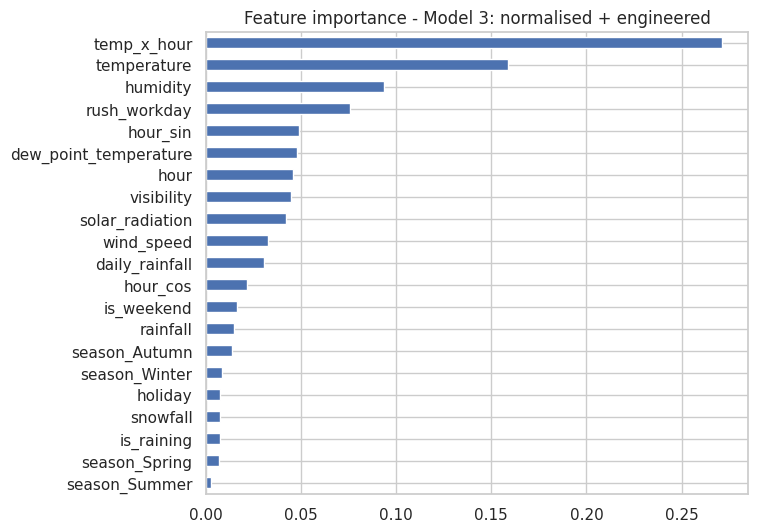

In [37]:
# Feature importance of the best model
best_name = max(dt_results, key=dt_results.get)
importance = pd.Series(dt_models[best_name].feature_importances_, index=feature_sets[best_name].columns)

importance.sort_values().plot(kind="barh", figsize=(7, 6), title="Feature importance - " + best_name)
plt.show()

## Task 5: Results Comparison Table

,Model 1: original (raw),Model 2: original (normalised),Model 3: normalised + engineered,Model 4: top 5 (normalised),Model 5: top 5 (raw)
Accuracy (%),78.07,77.95,83.23,73.37,73.25


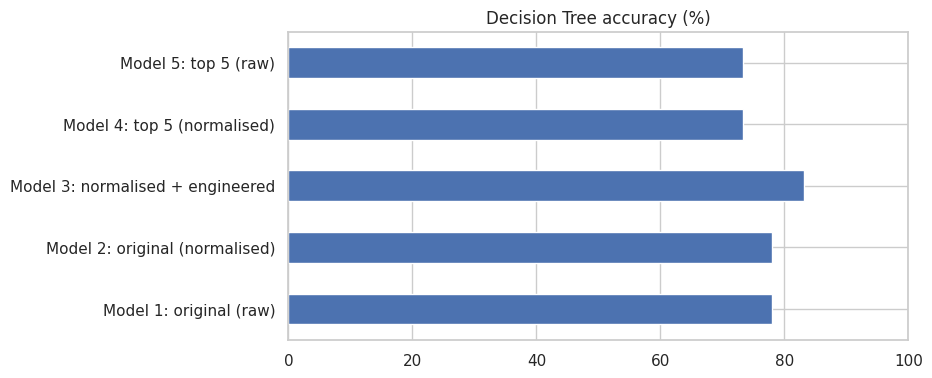

In [38]:
dt_table = pd.DataFrame([dt_results], index=["Accuracy (%)"]).round(2)
display(dt_table)

pd.Series(dt_results).plot(kind="barh", figsize=(8, 4), xlim=(0, 100), title="Decision Tree accuracy (%)")
plt.show()

## Task 6: Model Improvement (SVM)

In [39]:
from sklearn.svm import SVC

# Shuffle the data and save it to a CSV file
data = X_eng.copy()
data["demand_class"] = y
data = data.sample(frac=1, random_state=RANDOM_STATE)
data.to_csv("shuffled_seoulbike.csv", index=False)

X_svm = data.drop(columns="demand_class")
y_svm = data["demand_class"]

def evaluate(model, features):
    # Return [70/30 split accuracy, 5-fold CV accuracy]
    X_tr, X_te, y_tr, y_te = train_test_split(features, y_svm, test_size=0.3, random_state=RANDOM_STATE, stratify=y_svm)
    model.fit(X_tr, y_tr)
    split_acc = accuracy_score(y_te, model.predict(X_te)) * 100
    cv_acc = float(cross_val_score(model, features, y_svm, cv=5).mean()) * 100
    return [round(split_acc, 2), round(cv_acc, 2)]

svm_results = {}
svm_results["Baseline SVM (all 21 features)"] = evaluate(SVC(), X_svm)
print("SVM [split, CV]:", svm_results["Baseline SVM (all 21 features)"])

SVM [split, CV]: [85.44, 85.18]


## Task 7: Hyperparameter Tuning

In [40]:
# Try different kernels
for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    acc = cross_val_score(SVC(kernel=kernel), X_svm, y_svm, cv=5).mean() * 100
    print(kernel, round(acc, 2))

linear 78.3


poly 85.23


rbf 85.18


sigmoid 54.66


In [41]:
param_grid = {"kernel": ["rbf"], "C": [0.1, 1, 10, 100], "gamma": ["scale", 0.01, 0.1, 1]}
grid = GridSearchCV(SVC(), param_grid, cv=5, n_jobs=-1)
grid.fit(X_svm, y_svm)
best_params = grid.best_params_
print("Best parameters:", best_params)

svm_results["With hyperparameter tuning"] = evaluate(SVC(**best_params), X_svm)
print("Tuned SVM [split, CV]:", svm_results["With hyperparameter tuning"])

Best parameters: {'C': 100, 'gamma': 'scale', 'kernel': 'rbf'}


Tuned SVM [split, CV]: [87.57, 87.52]


## Task 8: Feature Selection

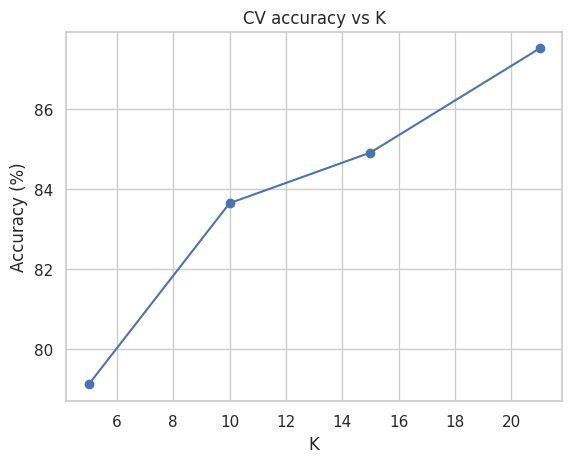

In [42]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import make_pipeline

# Choose K: compare CV accuracy for different K values (selection is refitted inside each fold)
k_scores = {}
for k in [5, 8, 10, 12, 14, 16, 18, 21]:
    model = make_pipeline(SelectKBest(f_classif, k=k), SVC(**best_params))
    k_scores[k] = cross_val_score(model, X_svm, y_svm, cv=5).mean() * 100

pd.Series(k_scores).plot(marker="o", title="CV accuracy vs K", xlabel="K", ylabel="Accuracy (%)")
plt.show()
pd.Series(k_scores).round(2)

In [43]:
selector = SelectKBest(f_classif, k=10).fit(X_svm, y_svm)
selected = X_svm.columns[selector.get_support()]
print("Selected features:", list(selected))

kbest_svm = make_pipeline(SelectKBest(f_classif, k=10), SVC(**best_params))
svm_results["With feature selection + tuning"] = evaluate(kbest_svm, X_svm)
print("K-Best SVM [split, CV]:", svm_results["With feature selection + tuning"])

Selected features: ['hour', 'temperature', 'dew_point_temperature', 'solar_radiation', 'season_Summer', 'season_Winter', 'temp_x_hour', 'hour_sin', 'rush_workday', 'is_raining']


K-Best SVM [split, CV]: [83.91, 83.65]


## Task 9: Dimensionality Reduction (PCA)

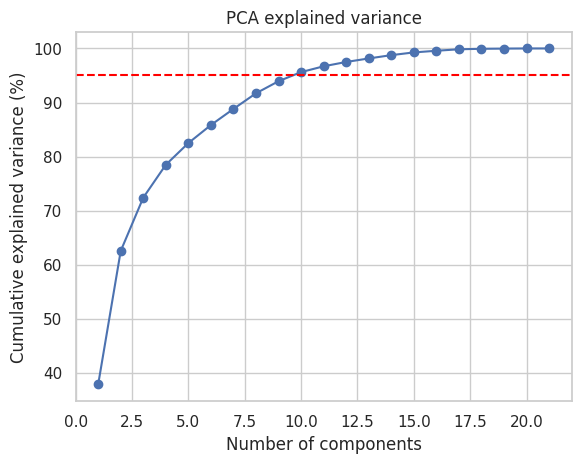

Variance kept by 10 components: 95.6 %


In [44]:
pca = PCA().fit(X_svm)
cum_var = np.cumsum(pca.explained_variance_ratio_) * 100
n_components = int(np.argmax(cum_var >= 95) + 1)   # smallest number of components reaching 95%

components = range(1, len(cum_var) + 1)
plt.figure(figsize=(9, 4))
plt.bar(components, pca.explained_variance_ratio_ * 100, label="Individual")
plt.plot(components, cum_var, marker="o", color="orange", label="Cumulative")
plt.axhline(95, color="red", linestyle="--", label="95% threshold")
plt.xlabel("Principal component")
plt.ylabel("Explained variance (%)")
plt.title("PCA explained variance")
plt.legend()
plt.show()

print(f"Components for >= 95% variance: {n_components} ({cum_var[n_components - 1]:.1f}%)")

In [45]:
pca_svm = make_pipeline(PCA(n_components=n_components, random_state=RANDOM_STATE), SVC(**best_params))

svm_results["With PCA + tuning"] = evaluate(pca_svm, X_svm)
print("PCA SVM [split, CV]:", svm_results["With PCA + tuning"])

PCA SVM [split, CV]: [86.9, 86.38]


## Task 10: Final Results Table

,Train-test split (%),Cross-validation (%)
Original features,85.44,85.18
With hyperparameter tuning,87.57,87.52
With feature selection + tuning,83.91,83.65
With PCA + tuning,86.90,86.38


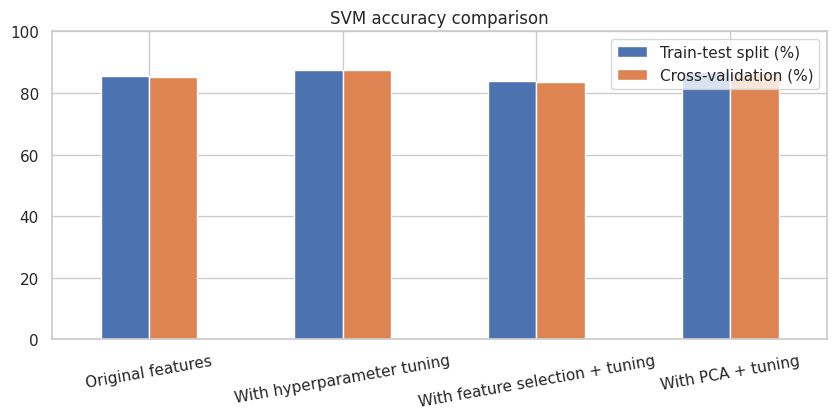

In [46]:
final_table = pd.DataFrame(svm_results, index=["Train-test split (%)", "Cross-validation (%)"]).T
display(final_table)

final_table.plot(kind="bar", figsize=(10, 4), rot=10, ylim=(0, 100), title="SVM accuracy comparison")
plt.show()